# **Clase 24 - 🎯 Repaso integrador de cara al Segundo Parcial**

### Laboratorio de Métodos Cuantitativos aplicados a la Gestión
**Tecnicatura Universitaria en Gestión y Análisis de Datos — FCE UBA**
Martes 3 de noviembre de 2026 · Unidades 4 y 5 · Clases 13 a 23

## ¿Qué vamos a hacer en esta clase?

Esta clase **no trae temas nuevos**. Todo lo que está acá lo vimos entre la clase 13 y la 23.

Hoy hacemos tres cosas: **ordenar** la segunda parte de la materia en diez bloques, ponerla en
cuadros que se puedan mirar de un saque, y **practicar** con ejercicios como los del parcial: leer una
salida, encontrar el error de un código y explicar qué significa un número para la organización.

La idea es que esta notebook les sirva de material de estudio para los días que quedan hasta el
**martes 17 de noviembre**.

## Objetivos de la clase

Al terminar, deberían poder:

1. **Elegir la herramienta** que corresponde a cada pregunta de gestión: ¿conviene el proyecto?,
   ¿llega la plata a fin de mes?, ¿cuánto riesgo hay?, ¿qué dicen los datos?
2. **Leer e interpretar** una salida: un VAN, un semáforo de caja, una integral, una simulación, una
   consulta SQL.
3. **Distinguir** lo que se confunde: proporción y equivalencia, TNA y CFTEA, ROI y VAN, rentable y
   líquido, `WHERE` y `HAVING`, media y mediana, seudonimizar y anonimizar.
4. **Detectar errores** en un código o en un razonamiento, sobre todo los que no dan error y devuelven
   un número equivocado.

## 🗺️ Qué entra en el segundo parcial

Entran las **Unidades 4 y 5**: las clases **13 a 23**. El formato, la duración y los materiales
permitidos los confirma la cátedra en el campus.

| Bloque | Clase | Qué conviene saber hacer |
|---|---|---|
| 1. Matemática financiera | 13 | Pasar de nominal a efectiva y entre plazos, mover plata en el tiempo, leer VAN, TIR y TIRM |
| 2. Métricas para invertir | 14 | ROI, CAGR, payback, IR, ROA y ROE, FTE: qué pregunta responde cada una y cuáles miran el tiempo |
| 3. Procesos y caja | 15 | DSO, DPO y ciclo de caja; flujo de caja con mora; runway y semáforo |
| 4. Datos con pandas | 15.5 | Nulos, duplicados, `groupby`, `merge` y sus cuatro tipos, leer una regresión |
| 5. Integrales | 16 | De lo marginal a lo total, acumulados, excedentes e impuestos, trapecio, inflación y Gini |
| 6. Simulación y muestreo | 19 | Semilla, muestra al azar contra muestra por conveniencia, sesgo, Monte Carlo para decidir |
| 7. Aplicaciones integradas | 20 | Una decisión mirada con todas las herramientas: CFTEA, WACC, tasa real, y cómo mentir con datos |
| 8. Métricas estadísticas | 21 | Media y mediana, desvío y CV, IQR y outliers, faltantes, correlación, gráfico de control |
| 9. SQL | 22 | Leer una consulta: `WHERE` y `HAVING`, `JOIN`, `NULL`, las formas de contar |
| 10. Anonimización y ética | 23 | Tipos de datos, seudonimizar contra anonimizar, k-anonimato, ruido, Ley 25.326 |

> Los ejercicios del final siguen el formato del primer parcial: **opción múltiple** y **ejercicios
> sobre un mismo caso**, con incisos de menor a mayor dificultad.

## 📖 Cómo usar esta notebook

- **Durante la clase:** recorremos los diez bloques en orden. Cada uno tiene la teoría en un cuadro,
  un ejemplo corto para correr y una tabla con los errores más comunes.
- **Después de la clase:** los cuadros resumen sirven de machete para estudiar, y al final hay
  **ejercicios tipo parcial** con la resolución escondida. Hacelos en papel antes de abrirla.
- **Todos los datos se generan acá adentro, con semilla**: la notebook corre entera sin descargar nada.

Arranquemos con las librerías de toda la clase.

In [1]:
# Las librerías de toda la clase (todas vienen instaladas en Colab)
import numpy as np                  # cálculos con números y arrays
import pandas as pd                 # tablas (DataFrame)
import matplotlib.pyplot as plt     # gráficos
import sympy as sp                  # cuentas simbólicas: integrales (clase 16)
import sqlite3                      # base de datos SQL que viene con Python (clase 22)
import hashlib, hmac                # funciones de hash (clase 23)
from sklearn.linear_model import LinearRegression   # regresión lineal (clase 15.5)

# numpy cambió el nombre de la regla del trapecio en la versión 2.0: esta línea anda con las dos
trapecio = getattr(np, "trapezoid", None) or np.trapz

pd.set_option("display.float_format", "{:,.2f}".format)   # números con separador de miles y 2 decimales
print("Librerías listas ✅")

Librerías listas ✅


---
# 💰 Bloque 1 — Matemática financiera (clase 13)

## La teoría en un cuadro

| Concepto | Qué es | Fórmula |
|---|---|---|
| **Tasa nominal (TNA)** | La tasa "de vidriera": se usa para anunciar y no capitaliza | — |
| **Tasa efectiva** | Lo que realmente rinde o cuesta en un período | — |
| **Proporción** | De una TNA a la tasa efectiva de $n$ días | $i_n = TNA \cdot \dfrac{n}{365}$ |
| **Equivalencia** | De una tasa efectiva a otra de distinto plazo | $i_2 = (1 + i_1)^{t_2/t_1} - 1$ |
| **Valor futuro y presente** | Llevar plata hacia adelante o traerla a hoy | $VF = VP\,(1+i)^n \qquad VP = \dfrac{VF}{(1+i)^n}$ |
| **Tasa real (Fisher)** | Cuánto se gana en poder de compra | $1 + r = \dfrac{1 + i}{1 + \pi}$ |
| **VAN** | Cuánta plata **de hoy** deja un proyecto | $VAN = \displaystyle\sum_{t=0}^{n} \dfrac{F_t}{(1+r)^t}$, con $F_0 = -I_0$ |
| **TIR** | La tasa que hace $VAN = 0$ | Conviene si $TIR > r$ |
| **TIRM** | Una TIR que reinvierte a una tasa realista | $\left(\dfrac{VF_{+}}{VP_{-}}\right)^{1/n} - 1$ |

**La regla de oro:** la **proporción** se usa solo con tasas **nominales**. Entre tasas **efectivas**
de distinto plazo, siempre **equivalencia**.

In [2]:
# Un plazo fijo: $1.000.000 a 30 días, con una TNA del 40%
capital, TNA, dias = 1_000_000, 0.40, 30

# 1) Proporción: de la TNA (nominal) a la tasa efectiva de 30 días. No capitaliza.
tasa_30d = TNA * dias / 365
monto = capital * (1 + tasa_30d)

# 2) Equivalencia: de la tasa de 30 días a la efectiva anual (TEA), renovando todo el año
TEA = (1 + tasa_30d) ** (365 / dias) - 1

# 3) Fisher: ¿le ganó a la inflación? Supongamos que ese mes los precios subieron 2,5%
inflacion_mes = 0.025
tasa_real = (1 + tasa_30d) / (1 + inflacion_mes) - 1

print(f"Tasa efectiva de 30 días    : {tasa_30d:.2%}")
print(f"Retira a los 30 días        : $ {monto:,.0f}")
print(f"TEA (si renueva todo el año): {TEA:.2%}")
print(f"Tasa real del mes           : {tasa_real:+.2%}")

Tasa efectiva de 30 días    : 3.29%
Retira a los 30 días        : $ 1,032,877
TEA (si renueva todo el año): 48.23%
Tasa real del mes           : +0.77%


La TNA anuncia 40%, pero el plazo fijo **rinde 3,29% en 30 días**, y si se renueva
todo el año la tasa efectiva anual es **48,2%**: la capitalización suma. Contra una
inflación de 2,5% en el mes, la ganancia **real** es de apenas **0,77%**.

In [3]:
# El horno de las clases 14 y 19: invertir $10 millones y cobrar estos flujos durante 5 años
flujos = [-10, 3, 3.5, 4, 4, 3]     # en millones; el año 0 es la inversión, con signo negativo
tasa = 0.20                         # costo de capital: lo que rinde la mejor alternativa

def van(flujos, tasa):
    # cada flujo se divide por (1 + tasa) elevado a su año; el año 0 queda igual (se divide por 1)
    return sum(f / (1 + tasa) ** t for t, f in enumerate(flujos))

def tir(flujos):
    # la TIR es la tasa que hace VAN = 0: la buscamos por bisección, como en la clase 13
    bajo, alto = -0.99, 10.0
    for _ in range(200):
        medio = (bajo + alto) / 2
        if van(flujos, medio) > 0:
            bajo = medio            # si el VAN todavía es positivo, la TIR está más arriba
        else:
            alto = medio
    return (bajo + alto) / 2

print(f"VAN al {tasa:.0%}: {van(flujos, tasa):+.2f} millones")
print(f"TIR      : {tir(flujos):.2%}")

VAN al 20%: +0.38 millones
TIR      : 21.68%


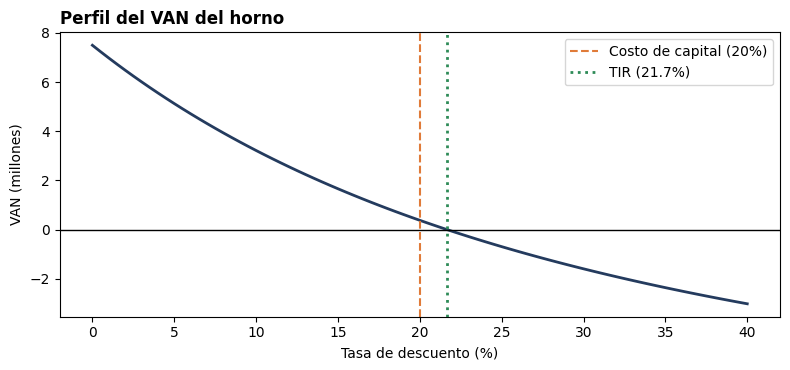

In [4]:
# El perfil del VAN: cómo cambia el VAN según la tasa. Donde la curva cruza el cero, está la TIR.
tasas = np.linspace(0, 0.40, 81)
vanes = [van(flujos, r) for r in tasas]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tasas * 100, vanes, color="#243b5e", lw=2)
ax.axhline(0, color="black", lw=1)
ax.axvline(tasa * 100, color="#e07b39", ls="--", label=f"Costo de capital ({tasa:.0%})")
ax.axvline(tir(flujos) * 100, color="#2e8b57", ls=":", lw=2, label=f"TIR ({tir(flujos):.1%})")
ax.set_xlabel("Tasa de descuento (%)")
ax.set_ylabel("VAN (millones)")
ax.set_title("Perfil del VAN del horno", loc="left", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

Al 20%, el VAN del horno es **+0,38 millones** y la TIR **21,7%**: conviene,
pero por poco. El gráfico muestra por qué VAN y TIR dicen lo mismo: el VAN es positivo para cualquier
tasa **menor** que la TIR, y negativo para cualquier tasa mayor.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Dividir una TEA por 12 para tener la mensual | Da una tasa mensual más alta que la real | Equivalencia: $(1 + TEA)^{1/12} - 1$ |
> | Usar proporción con una tasa efectiva | Se mezcla una tasa nominal con una efectiva | Proporción solo con la TNA |
> | Descontar también el año 0 | La inversión queda achicada y el VAN sale mal | El año 0 se divide por $(1+r)^0 = 1$ |
> | Elegir entre proyectos por la TIR | La TIR no mide plata: un proyecto chico puede tener TIR alta y dejar poco | Para elegir, el VAN |
> | Mezclar flujos nominales con una tasa real | El VAN sale sesgado | Nominal con nominal, real con real |

---
# 📈 Bloque 2 — Métricas para invertir (clase 14)

## La teoría en un cuadro

| Métrica | La pregunta que responde | Cómo se calcula | ¿Mira el tiempo? |
|---|---|---|---|
| **ROI** | ¿Cuánto gané por cada peso puesto? | $\dfrac{\text{recibido} - \text{invertido}}{\text{invertido}}$ | ❌ |
| **CAGR** | ¿Cuánto rindió **por año**? | $\left(\dfrac{\text{final}}{\text{inicial}}\right)^{1/\text{años}} - 1$ | ✅ (anualiza) |
| **Payback simple** | ¿Cuándo recupero la plata? | Años hasta que el acumulado llega a 0 | ❌ |
| **Payback descontado** | ¿Cuándo la recupero, en plata de hoy? | Lo mismo, con los flujos descontados | ✅ |
| **IR** | ¿Cuánto valor de hoy genera cada peso? | $\dfrac{VP_{\text{flujos}}}{I_0} = 1 + \dfrac{VAN}{I_0}$ | ✅ |
| **ROA** | ¿Cuánto rinde todo el activo? | $\dfrac{\text{resultado operativo}}{\text{activo}}$ | — |
| **ROE** | ¿Cuánto rinde la plata de los dueños? | $\dfrac{\text{resultado neto}}{\text{patrimonio}}$ | — |
| **FTE** | ¿Cuánto trabajo libera un proyecto? | $\dfrac{\text{horas de la tarea}}{\text{horas de una persona}}$ | — |

**IR > 1 es lo mismo que VAN > 0.** Y la diferencia entre ROA y ROE es la **deuda**: si cuesta menos
de lo que rinde el activo, el ROE sube (apalancamiento); si cuesta más, baja.

In [5]:
# Las métricas de la clase 14, sobre el mismo horno del bloque 1
def roi(recibido, invertido):
    return (recibido - invertido) / invertido                # cuánto gané por cada peso puesto

def cagr(inicial, final, años):
    return (final / inicial) ** (1 / años) - 1               # la tasa anual que lleva de inicial a final

def payback(flujos):
    # años hasta recuperar la inversión, interpolando dentro del año (None si nunca se recupera)
    acumulado = flujos[0]
    for año in range(1, len(flujos)):
        if acumulado + flujos[año] >= 0:
            return (año - 1) + (-acumulado) / flujos[año]
        acumulado += flujos[año]
    return None

inversion = -flujos[0]
descontados = [f / (1 + tasa) ** t for t, f in enumerate(flujos)]    # cada flujo en plata de hoy

print(f"ROI               : {roi(sum(flujos[1:]), inversion):.1%}   (no mira el tiempo)")
print(f"Payback simple    : {payback(flujos):.2f} años")
print(f"Payback descontado: {payback(descontados):.2f} años")
print(f"IR                : {sum(descontados[1:]) / inversion:.3f}   (= 1 + VAN / inversión)")
print(f"CAGR de una acción que pasó de 100 a 160 en 4 años: {cagr(100, 160, 4):.2%} anual (ROI: {roi(160, 100):.0%})")

ROI               : 75.0%   (no mira el tiempo)
Payback simple    : 2.88 años
Payback descontado: 4.68 años
IR                : 1.038   (= 1 + VAN / inversión)
CAGR de una acción que pasó de 100 a 160 en 4 años: 12.47% anual (ROI: 60%)


In [6]:
# ROA y ROE: la misma empresa, sin deuda, con deuda barata y con deuda cara (millones de pesos)
activo, resultado_operativo = 100, 20

for deuda, tasa_deuda in [(0, 0.00), (60, 0.10), (60, 0.30)]:
    roa = resultado_operativo / activo
    resultado_neto = resultado_operativo - tasa_deuda * deuda     # lo que queda después de pagar intereses
    roe = resultado_neto / (activo - deuda)                        # sobre la plata de los dueños (patrimonio)
    print(f"Deuda {deuda:>3} al {tasa_deuda:>3.0%}:  ROA {roa:.0%}  |  ROE {roe:.0%}")

# FTE: automatizar la carga de 3.000 facturas por mes, que bajan de 6 minutos a 1 minuto
HORAS_MES_PERSONA = 160
horas_liberadas = 3_000 * (6 - 1) / 60
print(f"\nHoras liberadas por mes: {horas_liberadas:.0f}  →  FTE liberados: {horas_liberadas / HORAS_MES_PERSONA:.2f}")

Deuda   0 al  0%:  ROA 20%  |  ROE 20%
Deuda  60 al 10%:  ROA 20%  |  ROE 35%
Deuda  60 al 30%:  ROA 20%  |  ROE 5%

Horas liberadas por mes: 250  →  FTE liberados: 1.56


El mismo horno, cinco miradas: el ROI dice **75%** y el payback simple **2,9 años**,
pero en plata de hoy recién se recupera a los **4,7 años**, sobre el final de su vida útil. Las
métricas que no miran el tiempo lo hacen parecer mucho mejor de lo que es.

Con el ROE se ve el apalancamiento: con deuda al 10% (menos de lo que rinde el activo, 20%) el ROE
sube a 35%; con deuda al 30%, cae a 5%.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Decidir con el ROI | No mira **cuándo** se cobra: un 75% en 1 año no es lo mismo que en 10 | Anualizar (CAGR) o usar VAN |
> | Decidir con el payback | Ignora todo lo que pasa después de recuperar la inversión | Usarlo como dato de riesgo, no como regla |
> | Leer el IR como "lo que gano" | IR = 1,04 no es 104% de ganancia: es 4% de VAN sobre la inversión | IR − 1 = VAN / inversión |
> | Creer que más deuda siempre sube el ROE | Solo lo sube si la deuda cuesta menos que el ROA | Comparar la tasa de la deuda con el ROA |
> | Horas liberadas = plata ahorrada | El ahorro solo existe si se hace algo con ese tiempo | Preguntar por qué canal se captura |

---
# 🏦 Bloque 3 — Procesos y caja (clase 15)

## La teoría en un cuadro

| Concepto | Qué mide | Cómo se calcula |
|---|---|---|
| **DSO** | Días promedio que se tarda en **cobrar** (proceso *order to cash*) | Promedio ponderado de los plazos de cobro |
| **DPO** | Días promedio que se tarda en **pagar** (proceso *procure to pay*) | Promedio ponderado de los plazos de pago |
| **CCC** (ciclo de caja) | Días que la plata "está en la calle" | $CCC = DSO - DPO$ |
| **Caja que inmoviliza el ciclo** | Cuánta plata hace falta para sostener la operación | ventas diarias $\times$ CCC |
| **Mora** | Cobranzas que se atrasan y no entran a tiempo | Cobranzas $\times (1 - \text{mora})$ |
| **Runway** | Cuántos meses de egresos cubre la caja | $\dfrac{\text{caja}}{\text{egreso mensual}}$ |

**Semáforo de la clase 15:** 🟢 más de 6 meses de runway · 🟡 de 3 a 6 · 🟠 de 1 a 3 · 🔴 menos de 1.

**La idea que atraviesa la clase:** rentable no es lo mismo que líquido. Una empresa puede ganar plata
y quedarse sin caja. **La caja manda.**

In [7]:
# Una PyME: cobra el 60% de las ventas en el momento y el 40% a 60 días; paga a sus proveedores a 15 días
dso = 0.60 * 0 + 0.40 * 60       # promedio ponderado de los días de cobro: 24 días
dpo = 15                         # días de pago
ccc = dso - dpo                  # ciclo de conversión de caja

ventas_mensuales = 3_000_000
ventas_diarias = ventas_mensuales / 30
print(f"DSO {dso:.0f} días  |  DPO {dpo:.0f} días  |  CCC {ccc:.0f} días")
print(f"Caja que inmoviliza el ciclo: $ {ventas_diarias * ccc:,.0f}")

DSO 24 días  |  DPO 15 días  |  CCC 9 días
Caja que inmoviliza el ciclo: $ 900,000


In [8]:
# Flujo de caja de 12 meses y escenarios de mora (como en la clase 15)
meses = np.arange(1, 13)
cobranzas = 3_000_000 * (1 + 0.15 * np.sin(2 * np.pi * meses / 12))   # ventas con estacionalidad
egresos = np.full(12, 2_600_000)
caja_inicial = 13_000_000

def caja_con_mora(mora):
    # mora: parte de las cobranzas que se atrasa y no entra en el mes
    saldo_mes = cobranzas * (1 - mora) - egresos
    return caja_inicial + saldo_mes.cumsum()          # caja acumulada mes a mes

def semaforo(caja, egreso_mensual):
    runway = caja / egreso_mensual                    # meses de egresos que cubre la caja
    if runway > 6:   return "🟢 verde", runway
    elif runway > 3: return "🟡 amarillo", runway
    elif runway > 1: return "🟠 naranja", runway
    else:            return "🔴 rojo", runway

filas = []
for mora in [0, 0.10, 0.20, 0.30, 0.40, 0.50]:
    caja = caja_con_mora(mora)
    estado, runway = semaforo(caja[-1], egresos.mean())
    filas.append({"mora": f"{mora:.0%}", "caja mínima": caja.min(), "caja final": caja[-1],
                  "runway (meses)": round(runway, 1), "semáforo": estado})
tabla_mora = pd.DataFrame(filas)
tabla_mora

,mora,caja mínima,caja final,runway (meses),semáforo
0,0%,"13,625,000.00","17,800,000.00",6.80,🟢 verde
1,10%,"13,302,500.00","14,200,000.00",5.50,🟡 amarillo
2,20%,"10,600,000.00","10,600,000.00",4.10,🟡 amarillo
3,30%,"7,000,000.00","7,000,000.00",2.70,🟠 naranja
4,40%,"3,400,000.00","3,400,000.00",1.30,🟠 naranja
5,50%,"-200,000.00","-200,000.00",-0.10,🔴 rojo


Sin mora, la PyME termina el año con 6,8 meses de caja (🟢). Con **10%** de
mora pasa a amarillo, con **30%** a naranja y con **50%** se queda sin caja (🔴). La empresa
es la misma y vende lo mismo: lo que cambia es **cuándo entra la plata**.

> 📌 **Sobre la escala del semáforo.** En la clase 20 (la integradora de Nodo Market) se usó otra escala,
> más corta, sobre la caja más baja del año. No hay una sola escala correcta: lo que importa es saber
> leer el semáforo **con la escala que te dan** y decir qué mide (¿caja actual, final o mínima?).

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Confundir rentable con líquido | Un proyecto con VAN positivo puede dejar la caja en rojo el mes que se paga | Mirar el flujo de caja mes a mes |
> | Leer un CCC negativo como un problema | Es al revés: se cobra antes de pagar, los proveedores financian la operación | CCC = DSO − DPO; negativo es cómodo |
> | Calcular el DSO sin ponderar | Un plazo de 60 días que pesa el 40% no da 60 días de DSO | Promedio **ponderado** por la proporción de ventas |
> | Calcular el runway con la caja equivocada | Caja actual, final y mínima dan semáforos distintos | Decir siempre qué caja se usa |

---
# 🐼 Bloque 4 — Datos con pandas (clase 15.5)

## La teoría en un cuadro

| Paso | Para qué | En pandas |
|---|---|---|
| **Mirar** | Saber qué hay antes de calcular nada | `head()`, `info()`, `describe()`, `shape` |
| **Nulos** | Encontrar los datos que faltan | `isnull().sum()`; después `fillna(...)` o `dropna()` |
| **Duplicados** | Que una venta no cuente dos veces | `duplicated().sum()`, `drop_duplicates(subset=...)` |
| **Resumir** | Un número por categoría | `groupby("col")["otra"].agg(...)` |
| **Unir** | Pegar dos tablas por una columna en común | `merge(otra, on="col", how=...)` |
| **Modelar** | Medir cuánto se asocian dos variables | `LinearRegression().fit(X, y)`: pendiente, ordenada, $R^2$ |

**Los cuatro `merge`:** `inner` deja solo lo que tiene pareja en las dos tablas · `left` todo lo de la
izquierda · `right` todo lo de la derecha · `outer` todo de las dos. Lo que no tiene pareja queda con `NaN`.

In [9]:
# Una tabla de ventas con problemas "de la vida real" y una tabla de precios
ventas = pd.DataFrame({
    "id":       [1, 2, 3, 4, 4, 5, 6, 7],
    "producto": ["Ibuprofeno", "Amoxicilina", "Insulina", "Protector solar", "Protector solar",
                 "Ibuprofeno", "Vitamina C", "Insulina"],
    "unidades": [2, 1, 3, np.nan, np.nan, 4, 2, 1],
})
precios = pd.DataFrame({
    "producto": ["Ibuprofeno", "Amoxicilina", "Insulina", "Protector solar"],    # falta la Vitamina C
    "precio":   [3_500, 9_800, 42_000, 18_000],
})

print("Nulos por columna:")
print(ventas.isnull().sum())
print("\nFilas duplicadas:", ventas.duplicated().sum())

Nulos por columna:
id          0
producto    0
unidades    2
dtype: int64

Filas duplicadas: 1


In [10]:
ventas = ventas.drop_duplicates()                                    # la venta 4 estaba cargada dos veces
ventas["unidades"] = ventas["unidades"].fillna(ventas["unidades"].median())    # supuesto: la mediana (hay que decirlo)

inner = ventas.merge(precios, on="producto", how="inner")            # solo lo que tiene pareja
left  = ventas.merge(precios, on="producto", how="left")             # todas las ventas
print("Ventas:", len(ventas), "| con inner:", len(inner), "| con left:", len(left))

left[left["precio"].isnull()]                                        # las ventas que el inner perdió sin avisar

Ventas: 7 | con inner: 6 | con left: 7


,id,producto,unidades,precio
5,6,Vitamina C,2.00,NaN


In [11]:
left["importe"] = left["unidades"] * left["precio"]
left.groupby("producto")["importe"].sum().sort_values(ascending=False)   # ojo: groupby suma el NaN como 0

producto
Insulina          168,000.00
Protector solar    36,000.00
Ibuprofeno         21,000.00
Amoxicilina         9,800.00
Vitamina C              0.00
Name: importe, dtype: float64

In [12]:
# Regresión lineal simple: ¿cuánto se asocian las ventas con la publicidad? (datos inventados con semilla)
rng = np.random.default_rng(15)
publicidad = rng.uniform(50, 150, 40)                              # miles de pesos por semana
ventas_semana = 800 + 6 * publicidad + rng.normal(0, 120, 40)      # miles de pesos por semana

X = publicidad.reshape(-1, 1)          # sklearn pide la X como una tabla de una columna
modelo = LinearRegression().fit(X, ventas_semana)
print(f"Pendiente: {modelo.coef_[0]:.2f}  |  Ordenada: {modelo.intercept_:.1f}  |  R²: {modelo.score(X, ventas_semana):.2f}")

Pendiente: 6.89  |  Ordenada: 720.2  |  R²: 0.76


**Cómo se lee:** por cada \$ 1.000 más de publicidad por semana, las ventas son en promedio unos
**\$ 6.888** más altas (pendiente 6,89). El $R^2$ de 0,76 dice que la publicidad explica
alrededor del 76% de las diferencias entre semanas. Tres cuidados: es **asociación, no causalidad**;
la ordenada (\$ 720.152) es lo que se vendería **sin** publicidad, un valor que está fuera de los datos
(no se observó ninguna semana sin publicidad); y no conviene usar la recta fuera del rango observado
(\$ 50.000 a \$ 150.000).

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Usar `inner` sin contar las filas | Se pierden en silencio las ventas sin pareja | Contar filas antes y después; buscar las perdidas con `left` + `isnull()` |
> | Sumar con duplicados | Las ventas repetidas inflan el total | `drop_duplicates()` antes de resumir |
> | Rellenar nulos sin decirlo | El dato inventado parece real | Explicar el supuesto (mediana, cero, categoría "sin dato") |
> | Creer que un `groupby` "vio" el `NaN` | `sum()` lo cuenta como 0 y la categoría parece no vender | Revisar `isnull()` antes de agrupar |
> | Leer la pendiente como causa | Una asociación no prueba que una cosa cause la otra | Hablar de "se asocia con" |

---
# ∫ Bloque 5 — Integrales (clase 16)

## La teoría en un cuadro

| Para qué | Qué integral | En Python |
|---|---|---|
| **De lo marginal a lo total** | Indefinida: $CT(q) = \int CMg\,dq + CF$ (la constante es el costo fijo) | `sp.integrate(f, q)` |
| **Un acumulado entre dos puntos** | Definida: $\int_a^b f(q)\,dq$ | `sp.integrate(f, (q, a, b))` |
| **Excedente del consumidor** | $EC = \int_0^{q^*} \left[P_d(q) - p^*\right] dq$ | ídem |
| **Excedente del productor** | $EP = \int_0^{q^*} \left[p^* - P_s(q)\right] dq$ | ídem |
| **Pérdida de peso muerto** | $DWL = \int_{q^t}^{q^*} \left[P_d(q) - P_s(q)\right] dq$ | ídem |
| **Cuando solo hay datos** | Regla del trapecio | `trapecio(y, x)` |
| **Inflación acumulada** | Se **multiplica**, no se suma: $\prod (1 + \pi_m) - 1$ | `np.prod(1 + pi) - 1` |
| **Desigualdad (Gini)** | $G = 1 - 2 \times$ área bajo la curva de Lorenz | `1 - 2 * trapecio(L, p)` |

In [13]:
q = sp.symbols("q", nonnegative=True)        # q: pedidos por día

# 1) De marginal a total: el costo marginal de un reparto (pesos por pedido) y su costo fijo diario
CMg = 200 + 4 * q
CF = 5_000
CT = sp.integrate(CMg, q) + CF               # la integral da el costo VARIABLE; la constante es el costo fijo
print("Costo total: CT(q) =", CT)

# 2) Integral definida: cuánto cuesta pasar de 50 a 80 pedidos por día
print("Costo de pasar de 50 a 80 pedidos:", sp.integrate(CMg, (q, 50, 80)), "pesos")

Costo total: CT(q) = 2*q**2 + 200*q + 5000
Costo de pasar de 50 a 80 pedidos: 13800 pesos


In [14]:
# 3) Excedentes: demanda P_d(q) = 100 - q y oferta P_s(q) = 20 + q
Pd = 100 - q
Ps = 20 + q
q_eq = sp.solve(sp.Eq(Pd, Ps), q)[0]             # equilibrio: donde se cruzan
p_eq = Pd.subs(q, q_eq)
EC = sp.integrate(Pd - p_eq, (q, 0, q_eq))       # lo que ganan los consumidores
EP = sp.integrate(p_eq - Ps, (q, 0, q_eq))       # lo que ganan los productores
print(f"Equilibrio: q = {q_eq}, p = {p_eq}  |  EC = {EC}  |  EP = {EP}")

# 4) Un impuesto de $10 por unidad: la oferta sube 10 y se pierde bienestar
impuesto = 10
q_t = sp.solve(sp.Eq(Pd, Ps + impuesto), q)[0]
DWL = sp.integrate(Pd - Ps, (q, q_t, q_eq))      # pérdida de peso muerto: lo que nadie se queda
print(f"Con impuesto: q = {q_t}  |  recauda {impuesto * q_t}  |  pérdida de peso muerto = {DWL}")

Equilibrio: q = 40, p = 60  |  EC = 800  |  EP = 800
Con impuesto: q = 35  |  recauda 350  |  pérdida de peso muerto = 25


In [15]:
# 5) Con datos: la inflación acumulada NO se suma, se multiplica
inflacion = np.array([3.0, 2.5, 2.8, 3.4, 2.2, 2.6]) / 100        # seis meses
print(f"Sumando (mal): {inflacion.sum():.1%}  |  Multiplicando (bien): {np.prod(1 + inflacion) - 1:.1%}")

# 6) Gini: la parte del ingreso de cada quinto de la población, del más pobre al más rico
quintiles = np.array([5, 10, 15, 25, 45]) / 100
p = np.linspace(0, 1, 6)                                  # 0%, 20%, ..., 100% de la población
L = np.concatenate([[0], np.cumsum(quintiles)])           # curva de Lorenz: ingreso acumulado
gini = 1 - 2 * trapecio(L, p)                             # 1 - 2 × área bajo la curva
print(f"Gini: {gini:.2f}")

Sumando (mal): 16.5%  |  Multiplicando (bien): 17.7%
Gini: 0.38


El impuesto recauda 350, pero el mercado se achica de 40 a 35 unidades: esas
unidades que valía la pena producir se pierden, y con ellas un bienestar de **25** que no se queda
nadie. La inflación de los seis meses no fue 16,5% sino
**17,7%**: cada aumento se aplica sobre precios que ya subieron.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Olvidar la constante al integrar el marginal | Se obtiene el costo **variable**, no el total | La constante es el costo fijo: sumarla |
> | Calcular el excedente como el área bajo la demanda | Se cuenta también lo que el consumidor pagó | Restar el precio: $\int (P_d - p^*)$ |
> | Sumar las inflaciones mensuales | Subestima la inflación acumulada | Multiplicar los factores $(1 + \pi)$ |
> | Un Gini fuera de 0 a 1 | Hay un error: la curva de Lorenz está mal armada | La curva arranca en 0, termina en 1 y queda debajo de la diagonal |

---
# 🎲 Bloque 6 — Simulación y muestreo (clase 19)

## La teoría en un cuadro

| Concepto | Qué es | En Python |
|---|---|---|
| **Semilla** | Hace que los números "al azar" se puedan repetir | `rng = np.random.default_rng(42)` |
| **Muestra al azar** | Cada caso tiene la misma chance de entrar | `df.sample(n, random_state=1)` |
| **Muestra estratificada** | Asegura la proporción justa de cada grupo | `df.groupby("grupo").sample(frac=0.1)` |
| **Muestra por conveniencia** | Se pregunta a quien es fácil preguntar | Produce **sesgo**: un error que va siempre para el mismo lado |
| **Tamaño de la muestra** | Más datos achican el error... cada vez menos | El error cae como $1/\sqrt{n}$ |
| **Monte Carlo** | Simular miles de futuros posibles y elegir la decisión que mejor funciona en todos | Un `for` que repite la cuenta |

**Monte Carlo no es Machine Learning:** en Monte Carlo vos ponés **la regla** y la computadora inventa
los datos; en Machine Learning vos ponés **los datos** y la computadora encuentra la regla.

In [16]:
rng = np.random.default_rng(19)      # semilla: así todos obtenemos los mismos números

# Una población de 10.000 clientes: el 30% compra por la app y gasta más
canal = rng.choice(["app", "mostrador"], size=10_000, p=[0.3, 0.7])
gasto = np.where(canal == "app", rng.normal(30_000, 6_000, 10_000), rng.normal(20_000, 5_000, 10_000))
clientes = pd.DataFrame({"canal": canal, "gasto": gasto})
verdad = clientes["gasto"].mean()    # en la vida real esto no lo conocemos

# 200 encuestas de 300 personas: al azar, y "por conveniencia" (solo clientes de la app)
azar = np.array([clientes.sample(300, random_state=i)["gasto"].mean() for i in range(200)])
solo_app = np.array([clientes[clientes["canal"] == "app"].sample(300, random_state=i)["gasto"].mean() for i in range(200)])

print(f"La verdad          : $ {verdad:,.0f}")
print(f"Encuestas al azar  : en promedio $ {azar.mean():,.0f}  (cada una se equivoca unos $ {np.abs(azar - verdad).mean():,.0f})")
print(f"Solo por la app    : en promedio $ {solo_app.mean():,.0f}  (cada una se equivoca unos $ {np.abs(solo_app - verdad).mean():,.0f})")

La verdad          : $ 22,975
Encuestas al azar  : en promedio $ 22,965  (cada una se equivoca unos $ 287)
Solo por la app    : en promedio $ 29,896  (cada una se equivoca unos $ 6,921)


In [17]:
# Más datos ayudan... cada vez menos (y no arreglan el sesgo)
for n in [50, 200, 800, 3_200]:
    error = np.mean([abs(clientes.sample(n, random_state=i)["gasto"].mean() - verdad) for i in range(200)])
    print(f"n = {n:>5}: error promedio $ {error:,.0f}")

n =    50: error promedio $ 684
n =   200: error promedio $ 390


n =   800: error promedio $ 170
n =  3200: error promedio $ 74


In [18]:
# Monte Carlo para decidir: ¿cuántas medialunas hornear? (los mismos datos y la misma semilla de la clase 19)
rng = np.random.default_rng(8)
demanda = rng.normal(120, 15, size=1_000).round()          # 1.000 días posibles

def ganancia_promedio(preparar, precio, costo, demanda):
    vendidas = np.minimum(demanda, preparar)                # se vende lo que piden, con el tope de lo preparado
    return (vendidas * precio - preparar * costo).mean()    # se cobran las vendidas; se paga TODO lo preparado

cantidades = np.arange(90, 161)
ganancias = [ganancia_promedio(c, 500, 200, demanda) for c in cantidades]
print(f"Conviene hornear {cantidades[np.argmax(ganancias)]} medialunas (la demanda promedio es 120)")

Conviene hornear 123 medialunas (la demanda promedio es 120)


In [19]:
# Monte Carlo del riesgo: el VAN del horno si cada flujo sale 20% mejor o peor de lo esperado
rng = np.random.default_rng(7)
esperados = np.array(flujos[1:])
años = np.arange(1, 6)

vans = []
for i in range(10_000):
    simulados = rng.normal(esperados, 0.20 * esperados)              # un futuro posible
    vans.append((simulados / (1 + tasa) ** años).sum() - inversion)
vans = np.array(vans)
print(f"VAN promedio: {vans.mean():+.2f} millones  |  probabilidad de perder plata: {(vans < 0).mean():.0%}")

VAN promedio: +0.37 millones  |  probabilidad de perder plata: 35%


Las encuestas al azar caen alrededor de la verdad; las de la app se pasan **siempre** para arriba, por
unos \$ 6.921: eso es **sesgo**, y no se arregla encuestando a más gente por
la app. En cambio, para las encuestas al azar, cuadruplicar la muestra **reduce el error más o menos a la mitad**.

En el horno, el VAN promedio sigue siendo positivo, pero en **35% de los futuros
se pierde plata**: el número solo (+0,38 millones) escondía ese riesgo.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Simular sin semilla | Nadie puede repetir los resultados | `np.random.default_rng(semilla)` |
> | Querer arreglar el sesgo con más datos | Se está más seguro de un número equivocado | Preguntar **quiénes** responden, no cuántos |
> | Preparar siempre "el promedio" | Lo óptimo depende de cuánto se pierde por faltar y por sobrar | Simular la ganancia para cada cantidad |
> | Leer el VAN como un número seguro | Esconde la chance de perder | Simular y mirar la probabilidad de VAN < 0 |

---
# 🧩 Bloque 7 — Aplicaciones económicas integradas (clase 20)

## La teoría en un cuadro

Una decisión (¿invierto en el depósito de Nodo Market?) se mira con **todas** las herramientas:

| Mirada | La pregunta | La herramienta |
|---|---|---|
| **Costo de la plata** | ¿Qué préstamo conviene? | CFTEA: todo lo que se paga (intereses, IVA, comisiones, seguro), no la TNA |
| **Costo del capital** | ¿Contra qué tasa comparo? | WACC: promedio ponderado del costo de la deuda (neta de impuestos) y del capital propio |
| **Rendimiento** | ¿Conviene? | VAN, TIR, payback, IR (en términos **reales** si los flujos están en pesos de hoy) |
| **Liquidez** | ¿Llega la plata a fin de mes? | Flujo de caja, mora, semáforo |
| **Riesgo** | ¿Qué tan seguro es? | Monte Carlo |
| **Honestidad** | ¿Cómo lo muestro sin engañar? | Lo que se **elige** (ventana, muestra), lo que se **calcula** (promedio o mediana, porcentaje o puntos) y lo que se **ve** (ejes, acumulados) |

$$WACC = \frac{E}{E + D}\,k_e + \frac{D}{E + D}\,k_d\,(1 - t)$$

In [20]:
# Comparar préstamos: la TNA más baja no siempre es la más barata (los bancos de la clase 20)
ofertas = pd.DataFrame({
    "TNA":            [0.300, 0.316],
    "Cargos mensual": [0.0085, 0.0025],          # seguro + comisión, por mes
}, index=["Banco Norte", "Banco Sur"])
IVA = 0.21                                       # IVA sobre los intereses

ofertas["TEM total"] = ofertas["TNA"] / 12 * (1 + IVA) + ofertas["Cargos mensual"]
ofertas["CFTEA"] = (1 + ofertas["TEM total"]) ** 12 - 1        # costo financiero total efectivo anual
ofertas.style.format("{:.2%}")

,TNA,Cargos mensual,TEM total,CFTEA
Banco Norte,30.00%,0.85%,3.87%,57.81%
Banco Sur,31.60%,0.25%,3.44%,50.00%


In [21]:
# El costo del capital (WACC) y su versión real (Fisher), con los números de la clase 20
propio, deuda_banco = 3.5, 5.5                   # millones: plata de los dueños y préstamo del banco
ke = 0.65                                        # lo que esperan ganar los socios (costo del capital propio)
kd = 0.50                                        # costo de la deuda: el CFTEA del Banco Sur, redondeado
imp_ganancias = 0.30                             # los intereses se descuentan de Ganancias (escudo fiscal)
total = propio + deuda_banco
wacc = propio / total * ke + deuda_banco / total * kd * (1 - imp_ganancias)
wacc_real = (1 + wacc) / (1 + 0.225) - 1         # Fisher, con una inflación esperada de 22,5%
print(f"WACC nominal: {wacc:.1%}  |  WACC real: {wacc_real:.1%}")

WACC nominal: 46.7%  |  WACC real: 19.7%


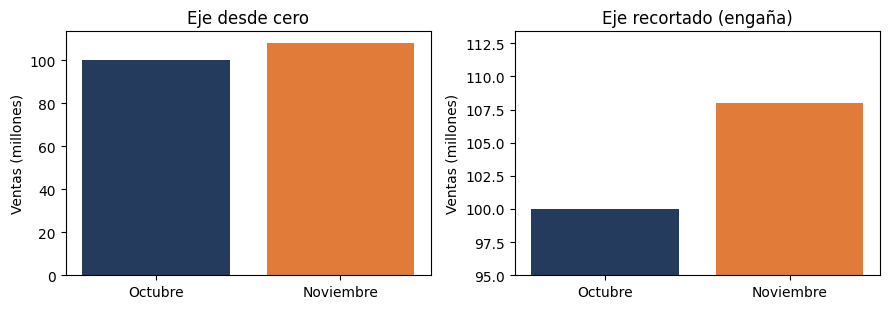

Las ventas crecieron 8%, pero en el recortado la barra parece crecer 160%


In [22]:
# Cómo mentir con datos: el mismo dato con el eje desde cero y con el eje recortado
octubre, noviembre = 100, 108                    # ventas en millones

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, piso, titulo in [(axs[0], 0, "Eje desde cero"), (axs[1], 95, "Eje recortado (engaña)")]:
    ax.bar(["Octubre", "Noviembre"], [octubre, noviembre], color=["#243b5e", "#e07b39"])
    ax.set_ylim(bottom=piso)
    ax.set_title(titulo)
    ax.set_ylabel("Ventas (millones)")
plt.tight_layout()
plt.show()
print(f"Las ventas crecieron {noviembre / octubre - 1:.0%}, pero en el recortado la barra parece crecer {(noviembre - 95) / (octubre - 95) - 1:.0%}")

El Banco Norte tiene la TNA más baja, pero su CFTEA es **57,8%** contra
**50,0%** del Banco Sur: los cargos se comen la ventaja. Y el WACC de
46,7% en pesos corrientes es de **19,7% en términos reales**: es la tasa que
corresponde si los flujos del proyecto están en pesos de hoy.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Elegir el préstamo por la TNA | Se ignoran IVA, comisiones y seguros | Comparar el CFTEA |
> | Descontar flujos en pesos de hoy con una tasa nominal | El proyecto parece peor de lo que es | Pesos constantes con tasa real |
> | Barras con el eje recortado | Una diferencia chica parece enorme | En barras, el eje arranca en cero |
> | Mostrar solo una ventana de tiempo | Se elige la historia que se quiere contar | Mostrar la serie completa o justificar la ventana |
> | Porcentaje contra puntos porcentuales | La mora de 10% a 20% "subió 10 puntos" o "se duplicó" | Decir cuál de las dos se usa |

---
# 📏 Bloque 8 — Métricas estadísticas (clase 21)

## La teoría en un cuadro

| Medida | Qué dice | Cuidado |
|---|---|---|
| **Media y mediana** | El valor típico | Con asimetría (pocos valores muy altos) la media se va para arriba: informar la mediana |
| **Asimetría** (`skew`) | Hacia dónde se estira la distribución | Mayor a 0: cola a la derecha (casi todas las variables de plata) |
| **Desvío estándar** | La distancia típica al promedio | Está en las unidades del dato |
| **Coeficiente de variación** | El desvío en % del promedio: $CV = s / \bar{x}$ | Sirve para comparar procesos de distinto tamaño |
| **Cuartiles e IQR** | El 50% central de los datos: $IQR = Q_3 - Q_1$ | No se deja arrastrar por los extremos |
| **Outliers** | Fuera de $[Q_1 - 1{,}5\,IQR \,;\, Q_3 + 1{,}5\,IQR]$ | Un outlier **no se borra automáticamente**: primero se pregunta qué es |
| **Faltantes** | Datos que no están | ¿Faltan al azar o con un patrón? Marcarlos con una bandera antes de imputar |
| **Correlación** | Relación **lineal** entre dos variables (−1 a 1) | No es causalidad; no ve curvas; un outlier la distorsiona |
| **Gráfico de control** | Media $\pm 3$ desvíos | Un punto afuera avisa que algo cambió |

In [23]:
# Tickets de dos sucursales (pesos): una pareja y otra con pocas compras muy grandes
rng = np.random.default_rng(21)
tickets = pd.DataFrame({
    "sucursal": ["Centro"] * 300 + ["Barrio"] * 300,
    "ticket": np.concatenate([rng.lognormal(np.log(12_000), 0.9, 300),     # muy asimétrica
                              rng.normal(12_000, 2_500, 300)]),            # pareja
})
resumen = tickets.groupby("sucursal")["ticket"].agg(["mean", "median", "std", "skew"])
resumen["CV"] = resumen["std"] / resumen["mean"]
resumen.round(2)

,mean,median,std,skew,CV
sucursal,,,,,
Barrio,"12,343.93","12,472.80","2,458.15",-0.24,0.20
Centro,"14,997.64","10,830.11","12,625.08",1.89,0.84


In [24]:
# Outliers con la regla del 1,5 · IQR, por sucursal
for sucursal, grupo in tickets.groupby("sucursal"):
    q1, q3 = grupo["ticket"].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = grupo[(grupo["ticket"] < q1 - 1.5 * iqr) | (grupo["ticket"] > q3 + 1.5 * iqr)]
    print(f"{sucursal}: límites [{q1 - 1.5 * iqr:,.0f} ; {q3 + 1.5 * iqr:,.0f}]  →  {len(fuera)} outliers")

Barrio: límites [6,581 ; 18,321]  →  7 outliers
Centro: límites [-13,330 ; 39,124]  →  19 outliers


In [25]:
# Faltantes: que falte un dato también es información (como en la base de créditos de la clase 21)
creditos = pd.DataFrame({
    "deuda_ingreso": [0.30, np.nan, 0.45, 0.28, np.nan, 0.52, 0.33, np.nan, 0.41, 0.25],
    "mora":          [0,    1,      1,    0,    1,      0,    0,    0,      0,    0],
})
creditos["falta_dato"] = creditos["deuda_ingreso"].isnull()      # la bandera, ANTES de imputar
creditos.groupby("falta_dato")["mora"].mean()                    # tasa de mora con y sin el dato

falta_dato
False   0.14
True    0.67
Name: mora, dtype: float64

In [26]:
# Correlación: mide relaciones LINEALES. Una relación perfecta en forma de U da cero.
x = np.linspace(-10, 10, 101)
print(f"Recta (y = 2x + 1): {np.corrcoef(x, 2 * x + 1)[0, 1]:.2f}  |  Parábola (y = x²): {np.corrcoef(x, x ** 2)[0, 1]:.2f}")

Recta (y = 2x + 1): 1.00  |  Parábola (y = x²): 0.00


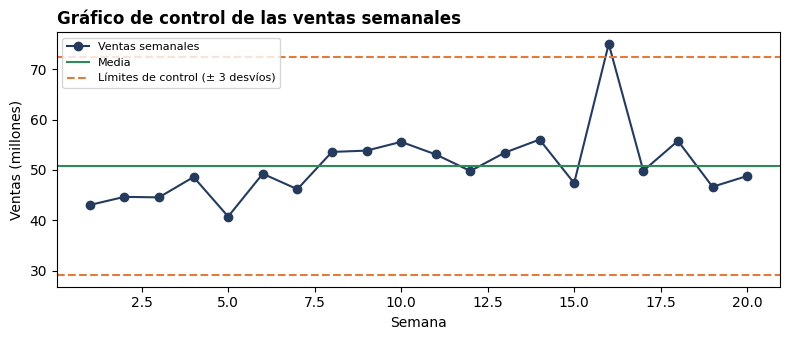

Semanas fuera de control: [16]


In [27]:
# Gráfico de control (como en la clase 21): 20 semanas de ventas, en millones
rng = np.random.default_rng(8)
semanal = pd.Series(rng.normal(50, 4, 20), index=range(1, 21))    # el índice es el número de semana
semanal[16] = 75                                                    # en la semana 16 pasó algo raro
media, desvio = semanal.mean(), semanal.std()
lim_sup, lim_inf = media + 3 * desvio, media - 3 * desvio          # límites de control: media ± 3 desvíos

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(semanal.index, semanal, marker="o", color="#243b5e", label="Ventas semanales")
ax.axhline(media, color="#2e8b57", label="Media")
ax.axhline(lim_sup, color="#e07b39", ls="--", label="Límites de control (± 3 desvíos)")
ax.axhline(lim_inf, color="#e07b39", ls="--")
ax.set_xlabel("Semana"); ax.set_ylabel("Ventas (millones)")
ax.set_title("Gráfico de control de las ventas semanales", loc="left", fontweight="bold")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fuera_control = semanal[(semanal > lim_sup) | (semanal < lim_inf)]
print("Semanas fuera de control:", list(fuera_control.index))

En el Centro la media (\$ 14.998) queda muy por encima de la mediana
(\$ 10.830): pocas compras grandes la arrastran, y su CV es de
84% contra 20% del Barrio. **Ahí se informa la mediana**, y el
Barrio es el proceso más predecible. En los créditos, la mora es de 67% cuando **falta** el dato y de
14% cuando está: si se rellenaba con el promedio, se borraba la señal más fuerte.

La parábola tiene correlación **0,00** aunque $y$ depende
**por completo** de $x$: la correlación solo ve rectas. Y en el gráfico de control, la semana
**16** queda fuera de los límites: no es mala suerte, algo pasó (una promoción, un feriado, un
error de carga) y hay que investigarlo.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Informar solo la media | Con asimetría, nadie "gana" ese promedio | Media y mediana, siempre las dos |
> | Comparar desvíos de cosas de distinto tamaño | Un desvío grande puede ser chico en proporción | Comparar el CV |
> | Borrar los outliers porque "ensucian" | Se tira justo la información más valiosa (fraude, mejores clientes) | Preguntar: ¿error de carga, caso real u otra población? |
> | Imputar sin bandera | Se pierde el dato de que faltaba, que puede predecir el resultado | Crear la columna "falta_dato" antes de imputar |
> | Creerle a una correlación sin graficar | No ve curvas y un outlier la inventa | Graficar antes de interpretar |

---
# 🗄️ Bloque 9 — SQL (clase 22)

## La teoría en un cuadro

```sql
SELECT   columnas, FUNCION(col) AS alias     -- qué quiero
FROM     tabla t                              -- de dónde
JOIN     otra o ON t.clave = o.clave          -- con qué tabla la cruzo
WHERE    condición sobre filas                -- qué filas (ANTES de agrupar)
GROUP BY columnas sin agregar                 -- cómo agrupo
HAVING   condición sobre grupos               -- qué grupos (DESPUÉS de agrupar)
ORDER BY columna DESC                         -- en qué orden
LIMIT    n                                    -- cuántas
```

| Se escribe | `SELECT` → `FROM` → `WHERE` → `GROUP BY` → `HAVING` → `ORDER BY` → `LIMIT` |
|---|---|
| **Se ejecuta** | `FROM` → `WHERE` → `GROUP BY` → `HAVING` → `SELECT` → `ORDER BY` → `LIMIT` |

| Lo que se confunde | |
|---|---|
| `WHERE` filtra **filas** antes de agrupar | `HAVING` filtra **grupos** después: es el que puede usar `SUM`, `COUNT`, `AVG` |
| `INNER JOIN`: solo lo que tiene pareja | `LEFT JOIN`: todo lo de la izquierda; lo que no tiene pareja queda con `NULL` |
| `COUNT(*)` cuenta **filas** | `COUNT(col)` cuenta **valores cargados** (saltea `NULL`); `COUNT(DISTINCT col)`, valores distintos |
| `= NULL` no encuentra nada (y no da error) | `IS NULL` es la forma correcta |

In [28]:
# Una base chica, en memoria (clase 22)
con = sqlite3.connect(":memory:")
pd.DataFrame({
    "id":       [1, 2, 3, 4, 5, 6, 7],
    "vendedor": ["Ana", "Ana", "Beto", "Beto", "Caro", "Caro", "Caro"],
    "producto": ["Ibuprofeno", "Insulina", "Insulina", "Jarabe", "Ibuprofeno", "Insulina", "Vitamina C"],
    "ciudad":   ["Centro", "Centro", "Cerro", None, "Alberdi", "Alberdi", "Cerro"],
    "total":    [7_000, 42_000, 84_000, 9_000, 14_000, 42_000, 6_000],
}).to_sql("ventas", con, index=False)
pd.DataFrame({"producto": ["Ibuprofeno", "Insulina", "Jarabe"],
              "categoria": ["Venta libre", "Receta", "Venta libre"]}).to_sql("productos", con, index=False)
pd.DataFrame({"vendedor": ["Ana", "Beto", "Caro", "Dani"],
              "sucursal": ["Centro", "Cerro", "Alberdi", "Centro"]}).to_sql("vendedores", con, index=False)

def sql(consulta):
    return pd.read_sql_query(consulta, con)      # manda la consulta a la base y devuelve un DataFrame

# WHERE filtra filas ANTES de agrupar; HAVING filtra grupos DESPUÉS
sql("""
    SELECT vendedor, COUNT(*) AS operaciones, SUM(total) AS facturacion
    FROM ventas
    WHERE total > 8000              -- solo las ventas de más de $8.000
    GROUP BY vendedor
    HAVING SUM(total) > 50000       -- solo los vendedores que, con esas ventas, superan $50.000
""")

,vendedor,operaciones,facturacion
0,Beto,2,93000
1,Caro,2,56000


In [29]:
# INNER contra LEFT: la Vitamina C no está en la tabla de productos
print("Ventas:", sql("SELECT COUNT(*) AS n FROM ventas")["n"][0])
print("Con INNER JOIN:", sql("SELECT COUNT(*) AS n FROM ventas v JOIN productos p ON v.producto = p.producto")["n"][0])

sql("""
    SELECT v.id, v.producto, p.categoria
    FROM ventas v
    LEFT JOIN productos p ON v.producto = p.producto
    WHERE p.producto IS NULL        -- las ventas que el INNER JOIN pierde
""")

Ventas: 7
Con INNER JOIN: 6


,id,producto,categoria
0,7,Vitamina C,None


In [30]:
# Después de un LEFT JOIN, COUNT(*) cuenta filas: a Dani (que no vendió nada) le da 1
sql("""
    SELECT ve.vendedor, COUNT(*) AS con_asterisco, COUNT(v.id) AS con_columna
    FROM vendedores ve
    LEFT JOIN ventas v ON v.vendedor = ve.vendedor
    GROUP BY ve.vendedor
""")

,vendedor,con_asterisco,con_columna
0,Ana,2,2
1,Beto,2,2
2,Caro,3,3
3,Dani,1,0


In [31]:
# NULL: "= NULL" no encuentra nada; "IS NULL" sí. Y lo mismo en pandas.
print("Con = NULL :", sql("SELECT COUNT(*) AS n FROM ventas WHERE ciudad = NULL")["n"][0])
print("Con IS NULL:", sql("SELECT COUNT(*) AS n FROM ventas WHERE ciudad IS NULL")["n"][0])
print("En pandas  :", sql("SELECT * FROM ventas")["ciudad"].isnull().sum())

Con = NULL : 0


Con IS NULL: 1
En pandas  : 1


Con `WHERE total > 8000` se descartan primero las ventas chicas; recién después se agrupa, y `HAVING`
deja solo a los vendedores que superan \$ 50.000 con lo que quedó. Ana queda afuera: tiene una venta
grande, pero con ella no llega.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | `WHERE SUM(total) > ...` | Error: cuando corre el `WHERE` los totales todavía no existen | Ese filtro va en `HAVING` |
> | `WHERE ciudad = NULL` | Devuelve 0 filas, sin error | `IS NULL` |
> | Olvidar el `ON` | Se cruza cada fila con cada fila (producto cartesiano) | Siempre `JOIN ... ON` |
> | `INNER JOIN` sin contar filas | Se pierden en silencio las filas sin pareja | Contar antes y después del `JOIN` |
> | `COUNT(*)` después de un `LEFT JOIN` | Cuenta 1 para quien no tiene nada | `COUNT(columna_de_la_derecha)` |

---
# 🔐 Bloque 10 — Anonimización y ética en el uso de datos (clase 23)

## La teoría en un cuadro

| Tipo de dato | Qué es | Ejemplos |
|---|---|---|
| **Identificador directo** | Identifica por sí solo a una persona | Nombre, DNI, CUIT, mail, teléfono |
| **Cuasi-identificador** | Solo no identifica, pero combinado con otros sí | Edad, sexo, barrio, código postal, fecha de nacimiento |
| **Atributo sensible** | Lo que se quiere proteger | Salud, ingresos, deudas, religión |

| Técnica | Qué hace | Ojo |
|---|---|---|
| **Seudonimizar** | Reemplaza el identificador por un código o un hash | Es **reversible**: el hash de un DNI se recupera probando todos los DNI |
| **Hash con clave (HMAC)** | Un hash que sin la clave secreta no se puede recalcular | La clave hay que guardarla |
| **k-anonimato** | Cada combinación de cuasi-identificadores aparece al menos $k$ veces | Si todo un grupo comparte el atributo sensible, se deduce igual (por eso existe la **l-diversidad**) |
| **Generalización y supresión** | Edad en rangos, barrio en zona; borrar los casos que quedan solos | Se pierde detalle: privacidad contra utilidad |
| **Ruido (Laplace)** | Suma un error aleatorio a cada dato | Cambia mucho a cada persona y poco los promedios |

**Marco legal:** la **Ley 25.326 de Protección de Datos Personales**, con la **Agencia de Acceso a la
Información Pública (AAIP)** como autoridad de aplicación. Los datos de **salud** son **datos sensibles** y
tienen una protección especial.

In [32]:
# Pacientes de una farmacia (inventados). Edad, sexo y barrio son cuasi-identificadores.
rng = np.random.default_rng(23)
n = 400
pacientes = pd.DataFrame({
    "dni":         rng.integers(20_000_000, 45_000_000, n),
    "edad":        rng.integers(18, 80, n),
    "sexo":        rng.choice(["F", "M"], n),
    "barrio":      rng.choice(["Centro", "Alberdi", "Cerro", "Güemes", "Nueva Córdoba"], n),
    "medicamento": rng.choice(["Insulina", "Enalapril", "Levotiroxina", "Atorvastatina"], n),
})

def k_por_registro(df, cuasi):
    # para cada fila: cuántas filas comparten su combinación de cuasi-identificadores
    return df.groupby(cuasi, observed=True)[cuasi[0]].transform("size")

k = k_por_registro(pacientes, ["edad", "sexo", "barrio"])
print(f"Con la edad exacta : k mínimo = {k.min()}  |  pacientes únicos (k = 1): {(k == 1).mean():.0%}")

# Generalización: la edad en tres rangos
pacientes["edad_rango"] = pd.cut(pacientes["edad"], bins=[17, 39, 59, 79], labels=["18-39", "40-59", "60-79"])
k2 = k_por_registro(pacientes, ["edad_rango", "sexo", "barrio"])
print(f"Con rangos de edad : k mínimo = {k2.min()}  |  pacientes únicos (k = 1): {(k2 == 1).mean():.0%}")

Con la edad exacta : k mínimo = 1  |  pacientes únicos (k = 1): 50%
Con rangos de edad : k mínimo = 7  |  pacientes únicos (k = 1): 0%


In [33]:
# Seudonimizar no es anonimizar: el hash de un DNI se puede revertir probando todos los DNI posibles
def hash_dni(dni):
    return hashlib.sha256(str(dni).encode()).hexdigest()

publicado = hash_dni(30_123_456)                       # lo que quedó publicado en lugar del DNI
for candidato in range(30_000_000, 30_200_000):         # probamos 200.000 DNI (en la vida real, todos)
    if hash_dni(candidato) == publicado:
        print("¡Encontrado! El DNI era", candidato)
        break

# Con una clave secreta (HMAC), sin la clave no se puede recalcular
CLAVE = b"una-clave-que-solo-tiene-la-farmacia"
print("Hash con clave:", hmac.new(CLAVE, b"30123456", hashlib.sha256).hexdigest()[:20], "...")

¡Encontrado! El DNI era 30123456
Hash con clave: a7c02e15e0154626b0ef ...


In [34]:
# Privacidad contra utilidad: ruido de Laplace sobre el gasto de 5.000 personas
gasto_mensual = rng.lognormal(np.log(20_000), 0.5, 5_000)
for escala in [1_000, 5_000, 20_000]:
    con_ruido = gasto_mensual + rng.laplace(0, escala, len(gasto_mensual))
    print(f"escala {escala:>6}: error por persona $ {np.abs(con_ruido - gasto_mensual).mean():>7,.0f}"
          f"  |  error en el promedio $ {abs(con_ruido.mean() - gasto_mensual.mean()):>5,.0f}")

escala   1000: error por persona $     983  |  error en el promedio $    13
escala   5000: error por persona $   5,116  |  error en el promedio $   149
escala  20000: error por persona $  19,976  |  error en el promedio $   267


Con la edad exacta, el **50%** de los pacientes es único en su combinación de edad, sexo y
barrio: cualquiera que sepa esos tres datos de un vecino puede averiguar qué medicamento toma, **sin saber su
nombre**. Con la edad en tres rangos, el k mínimo pasa de 1 a **7**. Y el ruido muestra el
equilibrio: con más ruido cada persona queda más protegida, pero el promedio casi no se mueve.

> ⚠️ **Errores clásicos de este bloque**
>
> | Error | Qué pasa | Cómo se evita |
> |---|---|---|
> | Creer que borrar el nombre alcanza | Los cuasi-identificadores combinados identifican igual | Medir el k-anonimato |
> | Llamar "anonimizar" a hashear el DNI | Es seudonimizar: se puede revertir | Hash con clave, o códigos aleatorios guardados aparte |
> | Generalizar todo "por las dudas" | Los datos dejan de servir para analizar | Generalizar lo justo y medir cuánto se perdió |
> | Pensar que la ética empieza al anonimizar | Empieza antes: qué datos necesito, para qué y con qué autorización | Pedir solo lo necesario (minimización) |

---
# 🗂️ Cuadros resumen (para los días que quedan)

## Cuadro 1 — Qué herramienta va con cada pregunta

| Si la pregunta es... | La herramienta es | Clase |
|---|---|---|
| ¿Cuánto rinde de verdad esta tasa? | Proporción (si es nominal) y equivalencia | 13 |
| ¿Cuánto vale hoy una plata que cobro en el futuro? | Valor presente | 13 |
| ¿Conviene el proyecto? | VAN (y TIR, IR) | 13, 14 |
| ¿Cuándo recupero la inversión? | Payback simple y descontado | 14 |
| ¿Le ganó a la inflación? | Fisher (tasa real) | 13, 20 |
| ¿Qué préstamo es más barato? | CFTEA | 20 |
| ¿Rinde el negocio o la plata de los dueños? | ROA y ROE | 14 |
| ¿Cuánto trabajo libera una automatización? | FTE | 14 |
| ¿Llega la plata a fin de mes? | Flujo de caja, CCC, runway, semáforo | 15 |
| ¿Cuánto por categoría? / ¿cómo junto dos tablas? | `groupby` / `merge` (o SQL: `GROUP BY` / `JOIN`) | 15.5, 22 |
| ¿Cuánto se asocian dos variables? | Correlación y regresión lineal | 15.5, 21 |
| ¿Cuál es el total si conozco el marginal? | Integral indefinida (+ la constante) | 16 |
| ¿Cuánto se acumula entre dos puntos? | Integral definida (o trapecio con datos) | 16 |
| ¿Cuánto ganan consumidores y productores? | Excedentes | 16 |
| ¿Cuánto le creo a una encuesta? | Muestreo: tamaño y, sobre todo, sesgo | 19 |
| ¿Cuánto preparo si la demanda es incierta? / ¿qué riesgo tiene el VAN? | Monte Carlo | 19, 20 |
| ¿Cuál es el valor típico? ¿Qué tan parejo es? | Media y mediana; desvío y CV | 21 |
| ¿Este dato es raro? | Regla del 1,5 · IQR (y después, preguntar qué es) | 21 |
| ¿El proceso se descontroló? | Gráfico de control | 21 |
| ¿Se puede identificar a alguien en esta base? | Tipos de datos y k-anonimato | 23 |

## Cuadro 2 — Las fórmulas que hay que saber de memoria

| Concepto | Fórmula |
|---|---|
| Proporción | $i_n = TNA \cdot n / 365$ |
| Equivalencia | $i_2 = (1 + i_1)^{t_2/t_1} - 1$ |
| Valor futuro / presente | $VF = VP(1+i)^n$ · $VP = VF/(1+i)^n$ |
| Fisher | $1 + r = (1 + i)/(1 + \pi)$ |
| VAN | $\sum_{t=0}^{n} F_t/(1+r)^t$ |
| IR | $1 + VAN/I_0$ |
| ROI · CAGR | $(R - I)/I$ · $(F/I)^{1/n} - 1$ |
| ROA · ROE | resultado operativo / activo · resultado neto / patrimonio |
| CCC | $DSO - DPO$ |
| Runway | caja / egreso mensual |
| CFTEA | $(1 + TEM_{\text{total}})^{12} - 1$ |
| WACC | $\frac{E}{E+D} k_e + \frac{D}{E+D} k_d (1 - t)$ |
| Costo total | $\int CMg\,dq + CF$ |
| Excedente del consumidor | $\int_0^{q^*} (P_d - p^*)\,dq$ |
| Inflación acumulada | $\prod (1 + \pi_m) - 1$ |
| Gini | $1 - 2 \times$ área bajo Lorenz |
| CV | $s / \bar{x}$ |
| Outliers | fuera de $[Q_1 - 1{,}5\,IQR;\ Q_3 + 1{,}5\,IQR]$ |

## Cuadro 3 — Los pares que se confunden

| | |
|---|---|
| **Proporción** (desde una TNA) | **Equivalencia** (entre tasas efectivas) |
| **TNA** (la de vidriera) | **CFTEA** (todo lo que se paga) |
| **Tasa nominal** (pesos corrientes) | **Tasa real** (poder de compra) |
| **VAN** (plata de hoy: sirve para elegir) | **TIR** (una tasa: no mide tamaño) |
| **Payback simple** | **Payback descontado** |
| **ROA** (el negocio) | **ROE** (la plata de los dueños) |
| **Rentable** (VAN > 0) | **Líquido** (llega la plata a fin de mes) |
| **DSO** (cobrar) | **DPO** (pagar) |
| **`inner`** (solo lo que tiene pareja) | **`left`** (todo lo de la izquierda) |
| **`WHERE`** (filas, antes de agrupar) | **`HAVING`** (grupos, después) |
| **`COUNT(*)`** (filas) | **`COUNT(col)`** (valores cargados) |
| **Integral indefinida** (una función total) | **Integral definida** (un número: el acumulado) |
| **Media** (se deja arrastrar) | **Mediana** (robusta) |
| **Desvío** (en unidades) | **CV** (en %, para comparar) |
| **Correlación** | **Causalidad** |
| **Muestra al azar** | **Muestra por conveniencia** (sesgo) |
| **Monte Carlo** (pongo la regla, genera datos) | **Machine Learning** (pongo datos, encuentra la regla) |
| **Seudonimizar** (reversible) | **Anonimizar** (irreversible) |

---
# 🧘 Cómo encarar el parcial

Ya pasaron por uno, así que esto es un recordatorio.

## Antes de arrancar

- **Leé todo el examen** antes de escribir: los ejercicios suelen ir sobre un mismo caso, y saber para
  dónde va la historia ayuda a responder el primero.
- **Arrancá por lo que te sale.** Dentro de cada ejercicio, los incisos van de menor a mayor dificultad.

## Mientras lo hacés

- **Escribí el planteo.** Qué herramienta usás y por qué. El procedimiento puntúa aunque el número final
  salga mal.
- **Unidades en cada resultado.** "0,92" no es una respuesta; "un VAN de \$ 0,92 millones" sí.
- **Cerrá con una frase de interpretación**: qué significa el número para la organización del caso.
  Es lo que más pesa y lo que más se olvida.
- **Desconfiá de los números que "dan bien" demasiado rápido.** En esta parte de la materia abundan los
  errores silenciosos: una tasa dividida por 12, un `inner` que pierde filas, un `= NULL` que devuelve
  cero, un hash que parece anónimo.
- **Si te trabás, pasá al siguiente** y volvé después.

> 💡 Y respirá. Si te bloqueás, soltá la lapicera treinta segundos y mirá otro ejercicio.

---
# 📝 Ejercicios de práctica

Seis ejercicios integradores, **más difíciles que lo que van a encontrar en el parcial**. Si estos
te salen, llegás bien.

> ⚠️ **Hacelos en papel primero**, sin correr nada, y recién después abrí la resolución. Correr el
> código antes de pensarlo es la mejor forma de creer que entendiste algo que no entendiste.

### El caso: **Farmacias del Sol**

Cadena de **tres farmacias en Córdoba** (Centro, Alberdi y Cerro). Vende a particulares y a afiliados
de **obras sociales**, que pagan más tarde. Está evaluando un **servicio de reparto a domicilio**. Los
seis ejercicios van sobre esta empresa.

---
### ✅ Ejercicio 1 — ¿Conviene el reparto? ¿Con qué plata? (clases 13, 14 y 20)

El reparto cuesta **\$ 24 millones** (motos, sistema y app) y se espera que deje estos flujos, en
millones de pesos de hoy, durante 5 años: **6,0 · 8,0 · 9,0 · 9,5 · 8,5**. El costo de
capital real de la cadena es **20%**. Una analista corrió las métricas y obtuvo:

| Métrica | Resultado |
|---|---|
| ROI | 70,8% |
| Payback simple | 3,11 años |
| Payback descontado | no se recupera en los 5 años |
| VAN al 20% | −0,24 millones |
| TIR | 19,6% |
| IR | 0,990 |

**a)** ¿Conviene el proyecto? Justificá con **dos** métricas que digan lo mismo.

**b)** El dueño dice: *"Un ROI de 71% y la plata vuelve en 3,1 años: es un negocio
espectacular"*. ¿Por qué esas dos métricas dicen una cosa y el VAN dice otra?

**c)** Otra analista calculó el VAN con este código y le dio **+4,51 millones**. El código corre
sin errores. ¿Dónde está el error, cómo se corrige, y por qué este error es más peligroso que uno que
rompe el programa?

```python
flujos = [-24, 6.0, 8.0, 9.0, 9.5, 8.5]
tasa = 0.20
van = sum(f / (1 + tasa) ** t for t, f in enumerate(flujos[1:])) - 24
```

**d)** Para financiar el reparto hay dos ofertas, las dos con IVA de 21% sobre los intereses y
capitalización mensual: el **Banco Andino** (TNA 31%, comisión de 0,8% mensual) y el **Banco Córdoba**
(TNA 34%, sin comisión). ¿Cuál conviene? Un compañero dice que la tasa mensual del Banco Córdoba es su
CFTEA dividido 12. ¿Qué error comete?

In [35]:
# Ejercicio 1 — probá acá tus respuestas (las funciones van, tir y payback están definidas en el bloque 1 y 2)

<details>
<summary><b>🔑 Ver resolución del Ejercicio 1</b></summary>

**a) No conviene, por poco.** El VAN es **negativo** (−0,24 millones): el proyecto deja menos
plata de hoy que la mejor alternativa al 20%. Lo confirman la **TIR** (19,6%, menor que el
costo de capital) y el **IR** (0,990, menor que 1). Las tres miden lo mismo: VAN < 0, TIR < r e IR < 1
van siempre juntos.

**b)** El ROI y el payback simple **no miran el tiempo**: tratan igual un peso de dentro de cinco años que
uno de hoy. El ROI suma los flujos (\$ 41 millones contra \$ 24) sin descontarlos, y el
payback simple dice cuándo vuelve la plata **sin descontar**. En plata de hoy, la inversión **no se recupera
dentro de los 5 años** (payback descontado). El reparto deja menos que la alternativa: el "negocio
espectacular" es una ilusión de no descontar.

**c)** `enumerate(flujos[1:])` arranca a contar en **0**, así que el flujo del **año 1 no se descuenta**, el
del año 2 se descuenta como si fuera del año 1, y así. Todo queda descontado un año de menos y el VAN sale
inflado: **+4,51** en lugar de **−0,24**. **Da vuelta la decisión.** Se corrige con
`enumerate(flujos[1:], start=1)`, o usando la función `van(flujos, tasa)` con la lista completa.

Es el error más peligroso porque **corre sin protestar** y devuelve un número con pinta razonable. Un
error que rompe el programa se arregla en el momento; este llega al informe del directorio.

**d) Conviene el Banco Córdoba**, aunque su TNA sea más alta. Hay que comparar el costo **total**:

| | TEM total | CFTEA |
|---|---|---|
| Banco Andino | 3,93% | **58,7%** |
| Banco Córdoba | 3,43% | **49,9%** |

La comisión mensual del Andino se come la ventaja de su TNA. El error del compañero: dividir una tasa
**efectiva** anual por 12 da 4,15%, una tasa mensual que capitalizada da más que el CFTEA. Entre tasas efectivas
se usa **equivalencia**: $(1 + 0{,}4986)^{1/12} - 1 = 3{,}43\%$, que es justamente la TEM total.

</details>

---
### ✅ Ejercicio 2 — ¿Llega la plata? ¿Qué dicen los tickets? (clases 15 y 21)

El **60%** de las ventas es a obras sociales, que pagan a **60 días**; el resto son particulares
que pagan en el momento. A la droguería se le paga a **30 días**. La cadena vende **\$ 50 millones por mes**.

**a)** Calculá el DSO, el DPO y el ciclo de caja (CCC). ¿Cuánta plata inmoviliza el ciclo? Interpretá.

**b)** Las obras sociales anuncian que van a pagar a **90 días**. ¿Qué pasa con el CCC y con la caja que
hace falta? ¿Cambió la rentabilidad de la cadena?

**c)** La cadena arranca el año con \$ 140 millones de caja y egresos de \$ 40 millones por mes. Simuló
cómo termina el año según la mora (la parte de las cobranzas que se atrasa):

| Mora | Caja final (millones) |
|---|---|
| 0% | 260 |
| 10% | 200 |
| 20% | 140 |
| 30% | 80 |
| 40% | 20 |

Con el semáforo de la clase 15 (🟢 más de 6 meses de runway · 🟡 3 a 6 · 🟠 1 a 3 · 🔴 menos de 1),
completá el runway y el color de cada escenario. ¿A partir de qué mora la cadena entra en zona naranja?
Proponé **una** palanca de proceso para no llegar ahí.

**d)** El resumen de los tickets (en pesos) de cada farmacia:

| Farmacia | Media | Mediana | Desvío |
|---|---|---|---|
| Centro | 18.500 | 12.300 | 21.000 |
| Alberdi | 11.200 | 10.800 | 3.400 |
| Cerro | 14.000 | 13.500 | 9.800 |

¿Qué farmacia tiene el proceso de venta más predecible? ¿En cuál conviene informar la mediana y por qué?
En el Centro, $Q_1 = 6.000$ y $Q_3 = 21.000$; aparece un ticket de **\$ 310.000** (un medicamento
oncológico). ¿Es outlier? ¿Qué harías con él?

In [36]:
# Ejercicio 2 — probá acá (la función semaforo está definida en el bloque 3)

<details>
<summary><b>🔑 Ver resolución del Ejercicio 2</b></summary>

**a)** El DSO es el promedio **ponderado** de los plazos de cobro:
$DSO = 0{,}60 \times 60 + 0{,}40 \times 0 = 36$ días. El DPO es 30
días, así que $CCC = 36 - 30 = 6$ días: la cadena financia **6 días** de operación con
plata propia. Con ventas diarias de \$ 1,67 millones, el ciclo inmoviliza unos
**\$ 10 millones**.

**b)** Con las obras sociales a 90 días, $DSO = 54$ y $CCC = 24$ días: **cuatro veces más**. La caja
inmovilizada pasa a unos **\$ 40 millones**. La rentabilidad **no cambió** (vende lo mismo, con el
mismo margen): lo que cambió es **cuándo entra la plata**. Rentable no es lo mismo que líquido.

**c)** Runway = caja final / \$ 40 millones:

| Mora | Caja final | Runway (meses) | Semáforo |
|---|---|---|---|
| 0% | 260 | 6,5 | 🟢 verde |
| 10% | 200 | 5,0 | 🟡 amarillo |
| 20% | 140 | 3,5 | 🟡 amarillo |
| 30% | 80 | 2,0 | 🟠 naranja |
| 40% | 20 | 0,5 | 🔴 rojo |

Con **30%** de mora entra en zona naranja, y con 40% en roja (le queda medio mes de egresos). Palancas de
proceso posibles: **facturar a las obras sociales más rápido** (presentar la documentación sin errores para
que no rechacen ni demoren), **negociar con la droguería un plazo mayor** (sube el DPO) o **empujar el pago
en el momento** entre los particulares. Cualquiera que achique el CCC sirve.

**d)** Se compara el **CV**, no el desvío: Centro 114%, Alberdi **30%**,
Cerro 70%. **Alberdi** es el más predecible. En el **Centro** la media
(\$ 18.500) está muy por encima de la mediana (\$ 12.300): hay asimetría (pocos tickets
muy altos), así que se informa la **mediana**.

El rango del Centro es $IQR = 21.000 - 6.000 = 15.000$, y el límite superior
$Q_3 + 1{,}5 \times IQR = 43.500$. El ticket de \$ 310.000 **es outlier**, pero **no se borra**: es una
venta **real** de un medicamento de alto costo. Se analiza aparte (quizás es otra "población": los
tratamientos especiales) y se informa el análisis con y sin él.

</details>

---
### ✅ Ejercicio 3 — Datos, consultas y privacidad (clases 15.5, 22 y 23)

**a)** La tabla `ventas` tiene **1.200 filas**. Al unirla con la tabla `precios` usando
`ventas.merge(precios, on="producto")` quedan **1.140**. Además, `ventas.duplicated().sum()` da **25**.
¿Qué pasó con las 60 filas? ¿Cómo las encontrás? ¿Qué hay que hacer con las 25 antes de calcular la
facturación?

**b)** Cada consulta tiene **un** error. Encontralo, decí qué devuelve (o si da error) y corregila.

```sql
-- (1) Farmacias que facturaron más de $5.000.000
SELECT sucursal, SUM(total) AS facturacion
FROM ventas
WHERE SUM(total) > 5000000
GROUP BY sucursal;

-- (2) Ventas sin obra social cargada
SELECT COUNT(*) FROM ventas WHERE obra_social = NULL;

-- (3) Operaciones de cada empleado, también de los que no vendieron
SELECT e.nombre, COUNT(*) AS operaciones
FROM empleados e
LEFT JOIN ventas v ON v.vendedor = e.nombre
GROUP BY e.nombre;
```

**c)** Para un estudio sobre adherencia a tratamientos, la cadena quiere compartir esta tabla con una
universidad:

| DNI | Nombre | Edad | Sexo | Barrio | Medicamento |
|---|---|---|---|---|---|
| 30.123.456 | Ana Gómez | 34 | F | Alberdi | Levotiroxina |
| 28.456.789 | Juan Pérez | 41 | M | Centro | Enalapril |
| 35.789.012 | Lucía Ríos | 27 | F | Cerro | Anticonceptivo |
| 31.234.567 | Marta Díaz | 38 | F | Alberdi | Insulina |
| 27.345.678 | Pedro Sosa | 45 | M | Centro | Atorvastatina |
| 36.456.789 | Sofía Luna | 22 | F | Cerro | Amoxicilina |
| 29.567.890 | Diego Vera | 49 | M | Centro | Metformina |
| 33.678.901 | Laura Paz | 31 | F | Alberdi | Insulina |

1. Clasificá cada columna: identificador directo, cuasi-identificador o atributo sensible.
2. Si se borran DNI y nombre, ¿cuál es el k-anonimato de la tabla (con edad, sexo y barrio)?
3. Si la edad se reemplaza por **décadas** (20-29, 30-39, 40-49), ¿qué k se logra? ¿Cuál es el grupo más chico?
4. Alguien propone, en lugar de borrar el DNI, reemplazarlo por su hash SHA-256. ¿Alcanza? ¿Qué ley aplica
   y qué tiene de especial este tipo de dato?

In [37]:
# Ejercicio 3 — probá acá (por ejemplo, armá la tabla de pacientes y usá la función k_por_registro del bloque 10)

<details>
<summary><b>🔑 Ver resolución del Ejercicio 3</b></summary>

**a)** Sin `how=`, `merge` hace un **`inner`**: se queda solo con las ventas cuyo producto está en la tabla de
precios. Las **60 filas** son ventas de productos **sin precio cargado**, y se perdieron sin aviso. Se encuentran
con un `left` y buscando los nulos:
`ventas.merge(precios, on="producto", how="left")` y después filtrar donde `precio` es nulo. Las **25 duplicadas**
hay que sacarlas con `drop_duplicates()` **antes** de sumar, o la facturación sale inflada.

**b)**
1. **Da error**: el `WHERE` corre **antes** de agrupar y los totales todavía no existen. El filtro va en
   `HAVING SUM(total) > 5000000`, **después** del `GROUP BY`.
2. **Devuelve 0, sin error**: comparar con `NULL` da "no sé", nunca verdadero. Va `WHERE obra_social IS NULL`.
3. **Corre, pero miente**: el empleado sin ventas aparece con **1** operación, porque `COUNT(*)` cuenta la fila
   vacía que arma el `LEFT JOIN`. Va `COUNT(v.id)` (una columna de la tabla de la derecha).

**c)**
1. **Identificadores directos:** DNI y nombre. **Cuasi-identificadores:** edad, sexo y barrio.
   **Atributo sensible:** el medicamento (dato de **salud**).
2. **k = 1**: con la edad exacta, **los 8 pacientes son únicos**. Quien sepa la edad, el sexo y el
   barrio de un vecino sabe qué medicamento toma, aunque no figure su nombre.
3. Con décadas, el **k mínimo es 2**. El grupo más chico es el de **mujeres de 20 a 29 años de Cerro**
   (2 personas); los otros dos grupos tienen 3. Ojo con la **l-diversidad**: en el grupo de mujeres de
   30 a 39 de Alberdi, 2 de 3 toman insulina; quien sepa que su vecina está en ese grupo
   puede adivinarlo con bastante seguridad.
4. **No alcanza**: es **seudonimizar**, no anonimizar. Como los DNI posibles son pocos (unas decenas de millones),
   se calcula el hash de todos y se compara: se revierte en minutos. Haría falta un hash **con clave secreta**
   (HMAC) o códigos aleatorios guardados aparte. Aplica la **Ley 25.326**: los datos de salud son **datos
   sensibles** y tienen protección especial, y además hace falta saber si los pacientes **autorizaron** ese uso.

</details>

---
### ✅ Ejercicio 4 — Vacunas, encuestas, repartos e inflación (clases 16 y 19)

**a)** Antes del invierno la cadena tiene que decidir cuántas dosis de vacuna antigripal pedir por semana.
Cada dosis se vende a **\$ 15.000** y cuesta **\$ 10.000**; la que sobra **se vence** y no se recupera nada. La
demanda semanal es incierta: en promedio **80 dosis**, con un desvío de 20. Una simulación de Monte Carlo
de 1.000 semanas dio:

| Dosis pedidas | Ganancia promedio por semana (\$) |
|---|---|
| 60 | 273.375 |
| 70 | 288.890 |
| 80 | 280.465 |
| 90 | 242.565 |
| 100 | 178.475 |

¿Cuántas conviene pedir? ¿Por qué **menos** que la demanda promedio, cuando en la clase 19 convenía hornear
**más** medialunas que el promedio?

**b)** Para estimar cuánto gasta un cliente por mes, la cadena encuestó a **2.000 clientes que compran por
la app**. ¿Qué problema tiene la encuesta? ¿Se arregla encuestando a 10.000 clientes de la app?

**c)** El costo marginal del reparto es $CMg(q) = 300 + 6q$ pesos por pedido ($q$ = pedidos por día), y el
costo fijo es de \$ 20.000 por día. Hallá el costo total $CT(q)$. ¿Cuánto cuesta pasar de 40 a 60 pedidos
por día?

**d)** En seis meses, los precios de los medicamentos subieron 4,0 · 3,5 · 3,0 · 2,8 · 2,5 · 3,2 (% mensual).
¿Cuánto subieron en el semestre? ¿Por qué no es 19,0%?

In [38]:
# Ejercicio 4 — la simulación de las vacunas (corrida con semilla: estos son los números del enunciado)
rng = np.random.default_rng(2026)
demanda_vacunas = rng.normal(80, 20, size=1_000).round().clip(min=0)    # dosis pedidas por semana
PRECIO_VAC, COSTO_VAC = 15_000, 10_000          # la dosis que sobra se vence: no se recupera nada

tabla_vacunas = pd.DataFrame({"pedir": [60, 70, 80, 90, 100]})
tabla_vacunas["ganancia promedio"] = [ganancia_promedio(c, PRECIO_VAC, COSTO_VAC, demanda_vacunas)
                                      for c in tabla_vacunas["pedir"]]
mejor_vacunas = np.arange(40, 121)[np.argmax([ganancia_promedio(c, PRECIO_VAC, COSTO_VAC, demanda_vacunas)
                                              for c in np.arange(40, 121)])]
tabla_vacunas.round(0)

,pedir,ganancia promedio
0,60,"273,375.00"
1,70,"288,890.00"
2,80,"280,465.00"
3,90,"242,565.00"
4,100,"178,475.00"


<details>
<summary><b>🔑 Ver resolución del Ejercicio 4</b></summary>

**a)** Conviene pedir **unas 72 dosis** por semana (la simulación completa, de 40 a 120, da el máximo en 72).
Lo óptimo no es el promedio: depende de **cuánto se pierde por faltar y por sobrar**. Acá, si falta una dosis
se pierde el margen (\$ 5.000); si sobra, se pierde el costo entero (\$ 10.000). Sobrar duele el doble que
faltar, así que conviene quedarse **corto**. Con las medialunas era al revés: faltar costaba \$ 300 de margen y
sobrar solo \$ 200, así que convenía pasarse. Es lo mismo que pasaba en el ejercicio 2 de la clase 19: cuando la
medialuna pasaba a costar \$ 350, sobrar dolía más que faltar y convenía hornear menos que el promedio.

**b)** Es una muestra **por conveniencia**: los clientes de la app no son como todos los clientes (por ejemplo,
suelen ser más jóvenes y gastar distinto). El error va **siempre para el mismo lado**: es **sesgo**. Encuestar a
10.000 por la app **no lo arregla**: solo da más seguridad sobre un número equivocado. Hace falta una muestra
**al azar** (o estratificada) de todos los clientes.

**c)** Integrando el marginal y sumando el costo fijo (la constante):
$CT(q) = 3 q^{2} + 300 q + 20000$. El costo de pasar de 40 a 60 pedidos es la integral **definida**:
$\int_{40}^{60} (300 + 6q)\,dq = 12000$ pesos por día, o sea \$ 600 por cada pedido adicional en promedio.

**d)** La inflación acumulada se **multiplica**:
$1{,}040 \times 1{,}035 \times 1{,}030 \times 1{,}028 \times 1{,}025 \times 1{,}032 - 1 = 20{,}56\%$.
No es 19,0% porque cada aumento se aplica sobre precios que **ya subieron**: es interés compuesto.

</details>

---
### ✅ Ejercicio 5 — Opción múltiple

Una sola opción correcta en cada una. Ojo que algunas son más retorcidas de lo que parecen.

---

**5.1** Un plazo fijo a 30 días paga una TNA de 40%. Con la convención de la clase 13, la tasa efectiva del período es:

&nbsp;&nbsp;&nbsp;(a) 3,33%, porque 40% / 12<br>
&nbsp;&nbsp;&nbsp;(b) 3,29%, porque 40% × 30 / 365<br>
&nbsp;&nbsp;&nbsp;(c) 2,80%, porque (1,40)^(30/365) − 1

**5.2** Dos proyectos que se excluyen: **A** tiene VAN de \$ 5 millones y TIR de 35%; **B**, VAN de \$ 9 millones y TIR de 28%. El costo de capital es 20%. Conviene:

&nbsp;&nbsp;&nbsp;(a) A, porque su TIR es más alta<br>
&nbsp;&nbsp;&nbsp;(b) cualquiera: los dos tienen VAN positivo<br>
&nbsp;&nbsp;&nbsp;(c) B, porque deja más plata de hoy

**5.3** Un proyecto tiene un **IR de 1,25**. Eso significa que:

&nbsp;&nbsp;&nbsp;(a) su VAN es el 25% de la inversión<br>
&nbsp;&nbsp;&nbsp;(b) su TIR es 25%<br>
&nbsp;&nbsp;&nbsp;(c) recupera el 25% de la inversión

**5.4** Una empresa tiene un ROA de 15% y toma deuda al 25%. Su ROE:

&nbsp;&nbsp;&nbsp;(a) sube, porque la deuda apalanca<br>
&nbsp;&nbsp;&nbsp;(b) baja, porque la deuda cuesta más de lo que rinde el activo<br>
&nbsp;&nbsp;&nbsp;(c) no cambia

**5.5** Una empresa tiene un **CCC de −5 días**. Eso significa que:

&nbsp;&nbsp;&nbsp;(a) cobra antes de pagar: los proveedores financian parte de la operación<br>
&nbsp;&nbsp;&nbsp;(b) pierde plata en cada venta<br>
&nbsp;&nbsp;&nbsp;(c) hay un error: el CCC no puede ser negativo

**5.6** Con el semáforo de la clase 15, una empresa con **\$ 12 millones** de caja y egresos de **\$ 3 millones** por mes está en:

&nbsp;&nbsp;&nbsp;(a) 🟢 verde<br>
&nbsp;&nbsp;&nbsp;(b) 🟠 naranja<br>
&nbsp;&nbsp;&nbsp;(c) 🟡 amarillo

**5.7** `ventas` tiene 500 filas y `ventas.merge(precios, on="producto")` devuelve 470. Las 30 que faltan son:

&nbsp;&nbsp;&nbsp;(a) filas duplicadas que el merge borró<br>
&nbsp;&nbsp;&nbsp;(b) ventas de productos que no están en `precios`<br>
&nbsp;&nbsp;&nbsp;(c) filas con nulos que el merge descarta

**5.8** $\int_0^{q} CMg(x)\,dx$, sin sumar nada más, da:

&nbsp;&nbsp;&nbsp;(a) el costo total<br>
&nbsp;&nbsp;&nbsp;(b) el costo medio<br>
&nbsp;&nbsp;&nbsp;(c) el costo variable total

**5.9** Si los precios suben 3% todos los meses durante un año, la inflación anual es:

&nbsp;&nbsp;&nbsp;(a) 36%<br>
&nbsp;&nbsp;&nbsp;(b) 42,6%<br>
&nbsp;&nbsp;&nbsp;(c) 3%

**5.10** La diferencia entre Monte Carlo y Machine Learning es que:

&nbsp;&nbsp;&nbsp;(a) son lo mismo con otro nombre<br>
&nbsp;&nbsp;&nbsp;(b) Monte Carlo es un tipo de ML<br>
&nbsp;&nbsp;&nbsp;(c) en Monte Carlo se pone la regla y se generan datos; en ML se ponen datos y se encuentra la regla

**5.11** Para estimar el gasto promedio de los clientes conviene más:

&nbsp;&nbsp;&nbsp;(a) una encuesta a 50.000 clientes de la app<br>
&nbsp;&nbsp;&nbsp;(b) una encuesta a 1.000 clientes elegidos al azar<br>
&nbsp;&nbsp;&nbsp;(c) da igual: lo que importa es el tamaño

**5.12** La sucursal A tiene ventas diarias con media 100 y desvío 20; la B, media 10 y desvío 5. Es más predecible:

&nbsp;&nbsp;&nbsp;(a) A, porque su CV es menor<br>
&nbsp;&nbsp;&nbsp;(b) B, porque su desvío es menor<br>
&nbsp;&nbsp;&nbsp;(c) son igual de predecibles

**5.13** Para saber qué ciudades facturaron más de \$ 1.000.000, la condición va:

&nbsp;&nbsp;&nbsp;(a) en `HAVING SUM(total) > 1000000`, después del `GROUP BY`<br>
&nbsp;&nbsp;&nbsp;(b) en `WHERE SUM(total) > 1000000`<br>
&nbsp;&nbsp;&nbsp;(c) en `WHERE total > 1000000`

**5.14** Una tabla tiene 200 filas y a 10 les falta la ciudad. `COUNT(*)` y `COUNT(ciudad)` dan, respectivamente:

&nbsp;&nbsp;&nbsp;(a) 200 y 200<br>
&nbsp;&nbsp;&nbsp;(b) 190 y 200<br>
&nbsp;&nbsp;&nbsp;(c) 200 y 190

**5.15** Reemplazar el DNI por su hash SHA-256 es:

&nbsp;&nbsp;&nbsp;(a) anonimizar: un hash no se puede revertir<br>
&nbsp;&nbsp;&nbsp;(b) cifrar con clave<br>
&nbsp;&nbsp;&nbsp;(c) seudonimizar: probando todos los DNI se recupera

**5.16** La correlación entre dos variables da 0,02. Eso significa que:

&nbsp;&nbsp;&nbsp;(a) no hay ninguna relación entre ellas<br>
&nbsp;&nbsp;&nbsp;(b) no hay relación **lineal**: puede haber una curva<br>
&nbsp;&nbsp;&nbsp;(c) una causa la otra, pero poco

<details>
<summary><b>🔑 Ver resolución del Ejercicio 5</b></summary>

**5.1 → (b).** La TNA es **nominal**: se pasa a la tasa del período con **proporción**, $40\% \times 30/365 = 3{,}29\%$.
La (a) usa 12 meses en lugar de días, y la (c) trata la TNA como si fuera una tasa efectiva anual (2,80%).

**5.2 → (c).** Para elegir entre proyectos que se excluyen manda el **VAN**: B deja \$ 4 millones más de hoy. La
TIR no mide tamaño: un proyecto chico puede tener una TIR altísima y dejar poca plata.

**5.3 → (a).** $IR = 1 + VAN/I_0$, así que $VAN/I_0 = 0{,}25$. Que el IR sea 1,25 no dice nada directo sobre la TIR.

**5.4 → (b).** La deuda solo apalanca si cuesta **menos** que el ROA. Al 25% contra un 15%, cada peso prestado rinde
menos de lo que cuesta, y la diferencia la pagan los dueños.

**5.5 → (a).** $CCC = DSO - DPO < 0$: se cobra antes de pagar. Es habitual en supermercados y comercio electrónico.

**5.6 → (c).** Runway = 12 / 3 = **4 meses**: entre 3 y 6, amarillo.

**5.7 → (b).** Sin `how=`, `merge` hace un `inner`: se pierden las ventas sin pareja. El merge no borra duplicados
ni descarta nulos por su cuenta.

**5.8 → (c).** La integral del marginal da el costo **variable**; para el total hay que sumar el costo fijo (la constante).

**5.9 → (b).** $1{,}03^{12} - 1 = 42{,}6\%$. La inflación se compone, no se suma.

**5.10 → (c).** Van al revés: Monte Carlo genera datos a partir de una regla; Machine Learning encuentra la regla a
partir de los datos.

**5.11 → (b).** La de la app tiene **sesgo**: más respuestas no lo arreglan. Mil casos al azar dan una estimación sin
sesgo y con un error chico.

**5.12 → (a).** Se compara el **CV**: A tiene 20%, B tiene 50%. El desvío de B es menor solo porque vende menos.

**5.13 → (a).** El filtro es sobre un **total por grupo**: va en `HAVING`. La (b) da error y la (c) responde otra
pregunta (ventas individuales de más de un millón).

**5.14 → (c).** `COUNT(*)` cuenta **filas** (200); `COUNT(ciudad)` cuenta valores **cargados** (190).

**5.15 → (c).** El hash es siempre el mismo para el mismo DNI y los DNI posibles son pocos: se puede revertir. Es
seudonimizar.

**5.16 → (b).** La correlación solo mide relaciones **lineales**. Una relación perfecta en forma de U da casi cero.
Siempre hay que graficar.

</details>

---
### ✅ Ejercicio 6 — El cierre integrador

**El que más gente subestima, y el que más rinde practicar.**

Con todo lo que analizaste en los ejercicios 1 a 4, escribí **un párrafo** dirigido al directorio de
Farmacias del Sol que responda: **¿lanzamos el reparto?, ¿qué riesgo de caja corremos?, ¿qué hay que
corregir en los datos?**

Condiciones:

- **Al menos tres vinculaciones concretas** a resultados de los ejercicios: un número, un hallazgo de los
  datos o una conclusión de la simulación.
- **Una recomendación explícita**, con el número que la respalda.
- **No repitas las cuentas: usalas.** El directorio ya sabe que las hiciste; quiere saber qué significan.

<details>
<summary><b>🔑 Ver un párrafo modelo y la rúbrica</b></summary>

**Un párrafo posible** (no es el único):

> Recomendamos **no lanzar el reparto en las condiciones actuales**: aunque recupera la plata en 3,1 años,
> en valor de hoy deja **\$ 0,24 millones menos** que la alternativa (su TIR, 19,6%, no alcanza el 20% que exigimos). Si se
> rediseña para mejorar los flujos, conviene financiarlo con el **Banco Córdoba** (49,9% de costo total
> contra 58,7%). El riesgo más urgente está en la caja: si las obras sociales pasan a pagar a 90 días, el
> ciclo de caja sube de 6 a 24 días y necesitamos unos \$ 40 millones inmovilizados; con una
> mora de 30% entraríamos en zona naranja. Antes de cualquier análisis hay que **corregir los datos**: el cruce de
> ventas con precios pierde 60 operaciones y hay 25 ventas duplicadas.

**Rúbrica:**

| Criterio | Qué se mira |
|---|---|
| Recomendación | Es explícita y la respalda un número (VAN, TIR o CFTEA) |
| Vinculaciones | Al menos tres resultados distintos, bien interpretados |
| Rentable contra líquido | Distingue si el proyecto conviene de si la caja aguanta |
| Calidad de los datos | Menciona que los números dependen de corregir el cruce y los duplicados |
| Lenguaje | Para un directorio: sin código ni fórmulas, con unidades |

</details>

---
# 🧭 Para llevarse

1. **Ninguna métrica alcanza sola.** El VAN dice si conviene, la caja si se puede pagar, la simulación cuánto
   riesgo hay y los datos qué es verdad.
2. **Las que no miran el tiempo engañan.** ROI y payback simple sirven de referencia, pero para decidir
   están el VAN, la TIR y el IR.
3. **Rentable no es lo mismo que líquido.** La caja manda: el CCC y el semáforo dicen si llega la plata.
4. **Los errores más caros no dan error:** una tasa dividida por 12, un `inner` que pierde filas, un
   `= NULL`, un `COUNT(*)` después de un `LEFT JOIN`, un hash que parece anónimo. Contá filas y verificá.
5. **Ningún número viaja solo.** Unidades y una frase de interpretación: es lo que más pesa en la corrección.

### 📚 Para seguir repasando

- Las notebooks de las clases **13 a 23** y sus presentaciones, que son la fuente de todo lo que está acá.
- Los ejercicios de cada notebook. Las de las clases 14, 16, 19, 20 y 22 traen las soluciones.
- La **clase de consultas** del **viernes 13 de noviembre** (virtual): traigan las dudas de esta notebook.

**¡Éxitos el martes 17!** 🍀